# 07 — OpenCV Edges & Gradients

This notebook covers image gradients, Sobel, Scharr, Laplacian, Canny edge detection, and the mathematics behind gradient-based edges.

**Goal:** understand how OpenCV detects rapid changes in intensity and turns them into useful edge maps.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("cat.jpg")
if image is None:
    raise FileNotFoundError("cat.jpg not found")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


## 1. What is an edge?

An edge is a location where image intensity changes rapidly. Examples include object boundaries, corners, text strokes, and strong texture transitions.

## 2. Image Gradient — The Math

The gradient measures how quickly intensity changes in the x and y directions:

$$
G_x = \frac{\partial I}{\partial x}, \qquad
G_y = \frac{\partial I}{\partial y}
$$

Gradient magnitude:

$$
|G| = \sqrt{G_x^2 + G_y^2}
$$

Gradient direction:

$$
\theta = \tan^{-1}\left(\frac{G_y}{G_x}\right)
$$

Large magnitude usually indicates a strong edge.

## 3. Sobel Operator

Sobel approximates the first derivative with convolution kernels:

$$
K_x =
\begin{bmatrix}
-1 & 0 & 1 \\
-2 & 0 & 2 \\
-1 & 0 & 1
\end{bmatrix},
\qquad
K_y =
\begin{bmatrix}
-1 & -2 & -1 \\
0 & 0 & 0 \\
1 & 2 & 1
\end{bmatrix}
$$

sobel X: (350, 525)

sobel y: (350, 525)


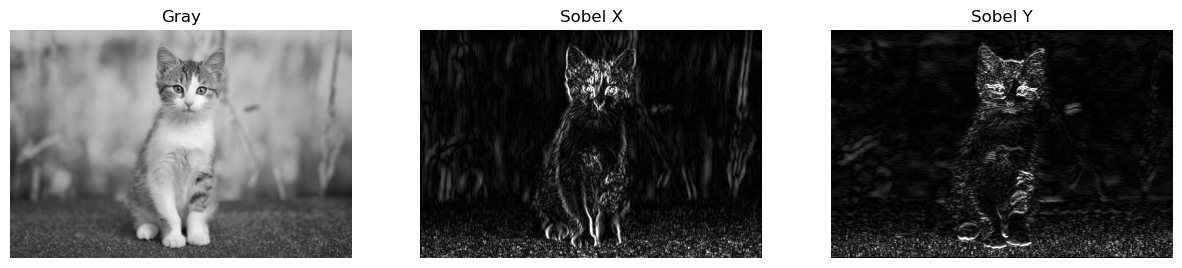

In [21]:
sobel_x=cv2.Sobel(gray,cv2.CV_64F,1,0,ksize=3)

sobel_y=cv2.Sobel(gray,cv2.CV_64F,0,1,ksize=3)

print(f"sobel X: {sobel_x.shape}\n\nsobel y: {sobel_y.shape}")

fig,ax=plt.subplots(1,3,figsize=(15,4))

for a,img,title in zip(ax,[gray,cv2.convertScaleAbs(sobel_x),cv2.convertScaleAbs(sobel_y)],["Gray","Sobel X","Sobel Y"]):
    a.imshow(img,cmap="gray")
    a.set_title(title)
    a.axis("off")

plt.show()

## 4. Sobel X vs Sobel Y

**Sobel X** responds strongly to vertical edges because intensity changes horizontally.

**Sobel Y** responds strongly to horizontal edges because intensity changes vertically.

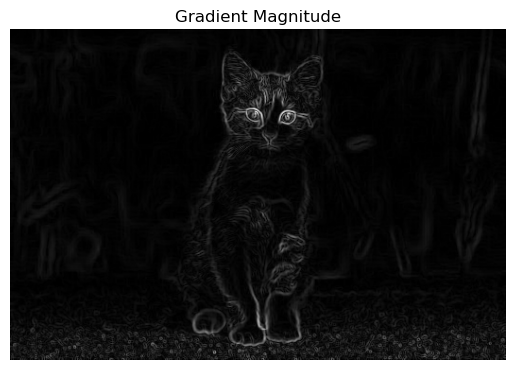

In [23]:
magnitude=cv2.magnitude(sobel_x.astype(np.float32),sobel_y.astype(np.float32))

magnitude=cv2.normalize(magnitude,None,0,255,cv2.NORM_MINMAX).astype(np.uint8)

plt.imshow(magnitude,cmap="gray")
plt.title("Gradient Magnitude")
plt.axis("off")
plt.show()

## 5. `cv2.Sobel()`

**Syntax:** `cv2.Sobel(src, ddepth, dx, dy, ksize)`

`dx` and `dy` select the derivative direction. `CV_64F` is a datatype it is useful because derivative results can be negative.

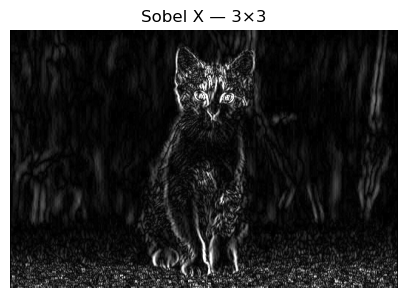

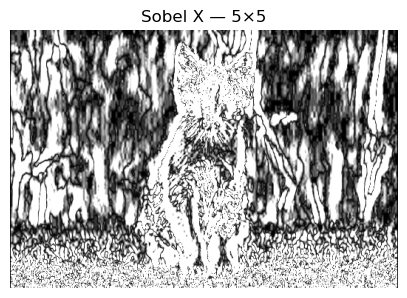

In [20]:
for k in [3,5]:
    s=cv2.Sobel(gray,cv2.CV_64F,1,0,ksize=k)
    plt.figure(figsize=(5,4))
    plt.imshow(cv2.convertScaleAbs(s),cmap="gray")
    plt.title(f"Sobel X — {k}×{k}")
    plt.axis("off")
    plt.show()

## 6. Scharr

Scharr is designed to give a more accurate 3×3 derivative than Sobel.

**Syntax:** `cv2.Scharr(src, ddepth, dx, dy)`

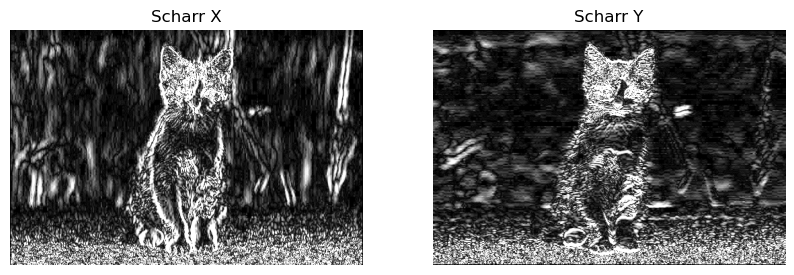

In [19]:
scharr_x=cv2.Scharr(gray,cv2.CV_64F,1,0)
scharr_y=cv2.Scharr(gray,cv2.CV_64F,0,1)
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a,img,title in zip(ax,[cv2.convertScaleAbs(scharr_x),cv2.convertScaleAbs(scharr_y)],["Scharr X","Scharr Y"]):
    a.imshow(img,cmap="gray")
    a.set_title(title)
    a.axis("off")
plt.show()

## 7. Laplacian

The Laplacian is the second derivative:

$$
\nabla^2 I =
\frac{\partial^2 I}{\partial x^2}
+
\frac{\partial^2 I}{\partial y^2}
$$

It responds to rapid intensity changes in all directions.

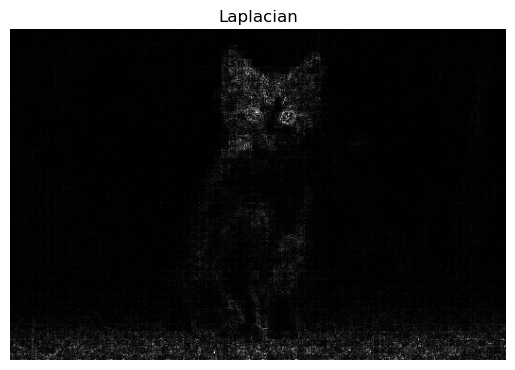

In [18]:
lap=cv2.Laplacian(gray,cv2.CV_64F)
plt.imshow(cv2.convertScaleAbs(lap),cmap="gray")
plt.title("Laplacian")
plt.axis("off")
plt.show()

## 8. Canny edge detector

Canny is a multi-stage detector:

1. Gaussian smoothing
2. Gradient calculation
3. Non-maximum suppression
4. Double threshold
5. Hysteresis edge tracking

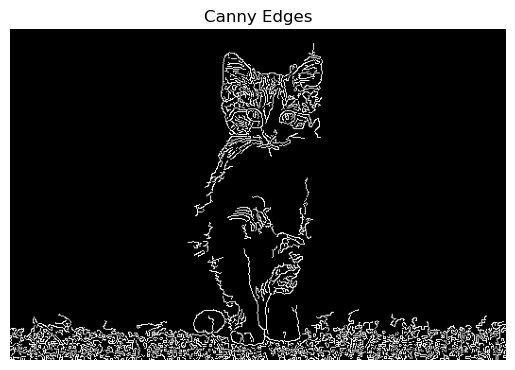

In [25]:
edges=cv2.Canny(gray,50,150)
plt.imshow(edges,cmap="gray")
plt.title("Canny Edges")
plt.axis("off")
plt.show()

## 9. Canny thresholds

The **high threshold** selects strong edges. The **low threshold** allows weaker candidates; weak edges survive when connected to strong edges through hysteresis.

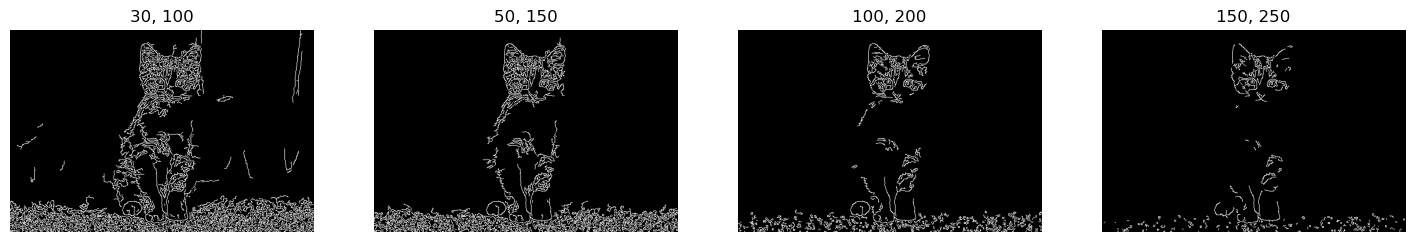

In [9]:
pairs=[(30,100),(50,150),(100,200),(150,250)]
fig,ax=plt.subplots(1,4,figsize=(18,4))
for a,(lo,hi) in zip(ax,pairs):
    a.imshow(cv2.Canny(gray,lo,hi),cmap="gray"); a.set_title(f"{lo}, {hi}"); a.axis("off")
plt.show()

## 10. Non-maximum suppression

Gradient regions can be thick. Non-maximum suppression keeps the strongest response along the gradient direction, producing thinner edges.

## 11. Hysteresis

Strong pixels become definite edges. Weak pixels are retained only when connected to strong edges; isolated weak pixels are removed.

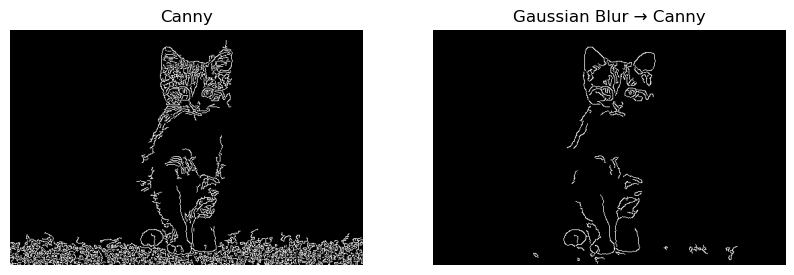

In [26]:
blur=cv2.GaussianBlur(gray,(5,5),0)
edge_raw=cv2.Canny(gray,50,150)
edge_blur=cv2.Canny(blur,50,150)
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a,img,title in zip(ax,[edge_raw,edge_blur],["Canny","Gaussian Blur → Canny"]):
    a.imshow(img,cmap="gray")
    a.set_title(title)
    a.axis("off")
plt.show()

## 12. Why blur before edge detection?

Derivatives amplify high-frequency changes, including noise. Gaussian smoothing reduces noise before calculating the gradient.

## 13. Edge overlay

A binary edge map can be drawn back onto the original image for visualization.

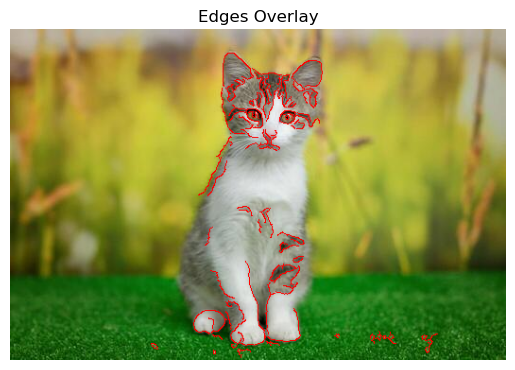

In [27]:
overlay=image.copy()
overlay[edge_blur>0]=(0,0,255)
plt.imshow(cv2.cvtColor(overlay,cv2.COLOR_BGR2RGB))
plt.title("Edges Overlay")
plt.axis("off")
plt.show()

## 14. Practical pipeline

**BGR → Grayscale → Gaussian Blur → Canny**

This is one of the most common classical edge-detection workflows.

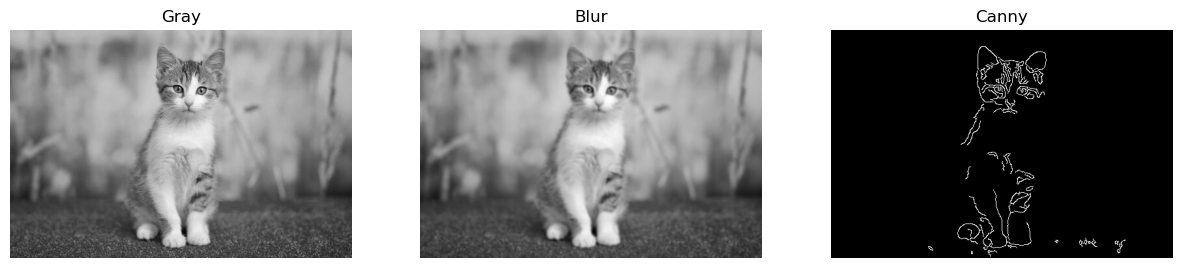

In [28]:
gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
blur=cv2.GaussianBlur(gray,(5,5),0)
edges=cv2.Canny(blur,50,150)
fig,ax=plt.subplots(1,3,figsize=(15,4))
for a,img,title in zip(ax,[gray,blur,edges],["Gray","Blur","Canny"]):
    a.imshow(img,cmap="gray")
    a.set_title(title)
    a.axis("off")
plt.show()

## 15. Sobel vs Scharr vs Laplacian vs Canny

| Method | Main idea | Typical use |
|---|---|---|
| Sobel | First derivative | Directional gradients |
| Scharr | Accurate 3×3 derivative | Accurate gradients |
| Laplacian | Second derivative | Rapid intensity changes |
| Canny | Multi-stage detector | Clean edge map |

## 16. Function cheat sheet

| Function | Purpose |
|---|---|
| `cv2.Sobel()` | First-order gradient |
| `cv2.Scharr()` | Accurate 3×3 gradient |
| `cv2.Laplacian()` | Second-order derivative |
| `cv2.Canny()` | Multi-stage edge detection |
| `cv2.magnitude()` | Gradient magnitude |
| `cv2.convertScaleAbs()` | Convert derivative output for display |